In [1]:
print("Hello PhishGuard")

Hello PhishGuard


In [2]:
!pip install streamlit

  Attempting uninstall: protobuf
    Found existing installation: protobuf 7.34.0
    Uninstalling protobuf-7.34.0:
      Successfully uninstalled protobuf-7.34.0


In [3]:
import pandas as pd

df = pd.read_csv("data/emails.csv")
print(df.shape)
print(df.columns)
df.head()

(82486, 2)
Index(['text_combined', 'label'], dtype='object')


,text_combined,label
0,hpl nom may 25 2001 see attached file hplno 52...,0
1,nom actual vols 24 th forwarded sabrae zajac h...,0
2,enron actuals march 30 april 1 201 estimated a...,0
3,hpl nom may 30 2001 see attached file hplno 53...,0
4,hpl nom june 1 2001 see attached file hplno 60...,0


In [4]:
print(df.isnull().sum())
print(df.iloc[:, -1].value_counts())

text_combined    0
label            0
dtype: int64
label
1    42891
0    39595
Name: count, dtype: int64


In [5]:
df = df.rename(columns={"Email Text": "text", "Email Type": "label"})
print(df.columns)

Index(['text_combined', 'label'], dtype='object')


In [7]:
print(df.columns.tolist())
df.head()

['text_combined', 'label']


,text_combined,label
0,hpl nom may 25 2001 see attached file hplno 52...,0
1,nom actual vols 24 th forwarded sabrae zajac h...,0
2,enron actuals march 30 april 1 201 estimated a...,0
3,hpl nom may 30 2001 see attached file hplno 53...,0
4,hpl nom june 1 2001 see attached file hplno 60...,0


In [9]:
df = df.rename(columns={"text_combined": "text"})
df = df[["text", "label"]]
print(df.columns.tolist())

['text', 'label']


In [10]:
print(df["label"].unique())
print(df["label"].value_counts())

[0 1]
label
1    42891
0    39595
Name: count, dtype: int64


In [11]:
print("Rows before:", len(df))

df = df.dropna(subset=["text", "label"])
print("After removing missing:", len(df))

df = df.drop_duplicates(subset=["text"])
print("After removing duplicates:", len(df))

df["label"] = df["label"].astype(int)
print(df["label"].value_counts())

Rows before: 82486
After removing missing: 82486
After removing duplicates: 82078
label
1    42845
0    39233
Name: count, dtype: int64


In [12]:
print("=== LABEL 0 ===")
for t in df[df["label"] == 0]["text"].head(3):
    print(t[:300], "\n")

print("=== LABEL 1 ===")
for t in df[df["label"] == 1]["text"].head(3):
    print(t[:300], "\n")

=== LABEL 0 ===
hpl nom may 25 2001 see attached file hplno 525 xls hplno 525 xls 

nom actual vols 24 th forwarded sabrae zajac hou ect 05 30 2001 12 07 pm enron capital trade resources corp eileen ponton 05 29 2001 08 37 davilal txu com cstonel txu com mjones 7 txu com hpl scheduling enron com liz bellamy enron com szajac enron com cc subject nom actual vols 24 th agree nominatio 

enron actuals march 30 april 1 201 estimated actuals march 30 2001 flow march 31 2001 flow april 1 2001 teco tap 35 000 receive actuals duke forward 

=== LABEL 1 ===
link dwl g 510 802 11 g wireless pci lan adapter 39 85 39 85 dwl g 510 high speed 2 4 ghz 802 11 g wireless pci lan adapter ieee 802 11 g standardupto 54 mbpsoperating frequency range 2 4 ghz ideal solution enabling wireless networking capabilities desktops pcs home office dwl g 510 visit http www c 

indemand payperview movies sports wed 15 sep 2004 11 33 14 0500 hi cable tv subscriber per per view filters lets get pay per view mature channe

In [13]:
df.to_csv("data/clean.csv", index=False)
print("Saved!")

Saved!


In [14]:
from sklearn.model_selection import train_test_split

X_train, X_temp, y_train, y_temp = train_test_split(
    df["text"], df["label"], test_size=0.30, stratify=df["label"], random_state=42)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=42)

print("Train:", len(X_train))
print("Validation:", len(X_val))
print("Test:", len(X_test))

Train: 57454
Validation: 12312
Test: 12312


In [15]:
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import classification_report

nb = Pipeline([
    ("tfidf", TfidfVectorizer(stop_words="english", max_features=50000, ngram_range=(1, 1))),
    ("clf", MultinomialNB())
])

nb.fit(X_train, y_train)
print(classification_report(y_val, nb.predict(X_val)))

              precision    recall  f1-score   support

           0       0.97      0.98      0.97      5885
           1       0.98      0.97      0.98      6427

    accuracy                           0.98     12312
   macro avg       0.98      0.98      0.98     12312
weighted avg       0.98      0.98      0.98     12312



In [16]:
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import precision_score, recall_score, f1_score
import pandas as pd

models = {
    "Naive Bayes": MultinomialNB(),
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Linear SVM": LinearSVC(),
}

results = []
for ngram in [(1, 1), (1, 2)]:
    for name, clf in models.items():
        pipe = Pipeline([
            ("tfidf", TfidfVectorizer(stop_words="english", max_features=50000, ngram_range=ngram)),
            ("clf", clf)
        ])
        pipe.fit(X_train, y_train)
        pred = pipe.predict(X_val)
        results.append({
            "model": name,
            "ngram": str(ngram),
            "precision": precision_score(y_val, pred),
            "recall": recall_score(y_val, pred),
            "f1": f1_score(y_val, pred),
        })

results_df = pd.DataFrame(results).round(4)
results_df

,model,ngram,precision,recall,f1
0,Naive Bayes,"(1, 1)",0.9833,0.9693,0.9763
1,Logistic Regression,"(1, 1)",0.9833,0.9880,0.9856
2,Linear SVM,"(1, 1)",0.9905,0.9918,0.9911
3,Naive Bayes,"(1, 2)",0.9904,0.9589,0.9744
4,Logistic Regression,"(1, 2)",0.9856,0.9879,0.9867
5,Linear SVM,"(1, 2)",0.9908,0.9932,0.9920


In [17]:
best = Pipeline([
    ("tfidf", TfidfVectorizer(stop_words="english", max_features=50000, ngram_range=(1, 2))),
    ("clf", LogisticRegression(max_iter=1000))
])
best.fit(X_train, y_train)
print("Trained!")

Trained!


              precision    recall  f1-score   support

           0       0.99      0.98      0.98      5885
           1       0.98      0.99      0.99      6427

    accuracy                           0.99     12312
   macro avg       0.99      0.99      0.99     12312
weighted avg       0.99      0.99      0.99     12312

ROC-AUC: 0.9986844211687127


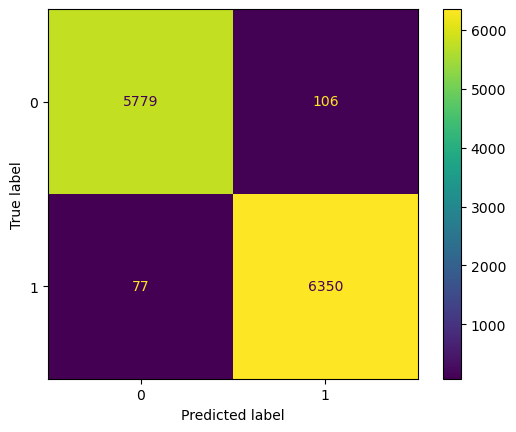

In [18]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, roc_auc_score
import matplotlib.pyplot as plt

pred = best.predict(X_test)
proba = best.predict_proba(X_test)[:, 1]

print(classification_report(y_test, pred))
print("ROC-AUC:", roc_auc_score(y_test, proba))

ConfusionMatrixDisplay(confusion_matrix(y_test, pred)).plot()
plt.savefig("confusion_matrix.png")
plt.show()

In [19]:
errors = X_test[pred != y_test]
true_labels = y_test[pred != y_test]

print("Total mistakes:", len(errors))
for text, label in list(zip(errors, true_labels))[:5]:
    print("TRUE LABEL:", label)
    print(text[:300], "\n")

Total mistakes: 183
TRUE LABEL: 0
california prices fun 

TRUE LABEL: 1
nita moreland mallorycurlewwestbrookmyfloridalegalcom horizontal monad clytemnestra hugging intramolecular cometary intramolecular horizontal munch angel hillel hydrodynamic anatomy hugging medium louisville perfectible utah cogent hydrodynamic critter cogent maxwell turbojet furtive annul unit wrot 

TRUE LABEL: 0
happy holidays wish wonderful holidays happy happy new year many blessings shirley 

TRUE LABEL: 1
venture reporter newsrisingtidestudioscom cmshttpwwwcmsummitcomimagesright_02gif cmshttpwwwcmsummitcomimagescms_titlegif dear friends online content business fantastic sound crazy perhaps advertising online taking chin past two years online content sites shutting laying staff pulling back offerings  

TRUE LABEL: 0
6 1119 disc kinship terms 1113 steven straight comments brevity son sole factor involved since dad mom pattern father mother son different used true vocative used usuallypostposed bonding form br

In [20]:
import numpy as np

tfidf = best.named_steps["tfidf"]
clf = best.named_steps["clf"]
words = np.array(tfidf.get_feature_names_out())
order = np.argsort(clf.coef_[0])

print("Top 20 words/phrases pointing to SAFE:")
print(words[order[:20]])
print()
print("Top 20 words/phrases pointing to PHISHING:")
print(words[order[-20:]])

Top 20 words/phrases pointing to SAFE:
['wrote' 'enron' 'thanks' 'opensuse' 'university' 'vince' 'im' 'language'
 'perl' 'louise' 'ierant' '713' 'questions' 'attached' 'pm' 'date'
 'february' '2001' '2007' 'tony']

Top 20 words/phrases pointing to PHISHING:
['viagra' 'quality' 'aug 2008' 'meds' 'bank' 'company' 'men' 'site'
 'remove' 'watches' 'replica' '2004' 'click' 'life' 'josemonkeyorg' 'love'
 'money' '0300' 'http' 'account']


In [21]:
def explain(text, top_n=8):
    vec = tfidf.transform([text])
    contrib = vec.toarray()[0] * clf.coef_[0]
    prob = clf.predict_proba(vec)[0][1]
    top_phish = np.argsort(contrib)[-top_n:][::-1]
    top_safe = np.argsort(contrib)[:top_n]
    return prob, [(words[i], contrib[i]) for i in top_phish if contrib[i] > 0], \
                 [(words[i], contrib[i]) for i in top_safe if contrib[i] < 0]

prob, phish_words, safe_words = explain(
    "urgent verify your account now click the link to avoid suspension")
print("Phishing risk:", round(prob * 100, 1), "%")
print("Phishing words:", phish_words)
print("Safe words:", safe_words)

Phishing risk: 97.4 %
Phishing words: [('account', np.float64(1.1783817956010045)), ('click', np.float64(0.9076826170423927)), ('verify', np.float64(0.5216296003924015)), ('urgent', np.float64(0.37894358253532306)), ('verify account', np.float64(0.2155295630066568)), ('suspension', np.float64(0.1483596328437304)), ('avoid', np.float64(0.1208180214060139)), ('link', np.float64(0.08825892688459158))]
Safe words: [('click link', np.float64(-0.15747723019521329)), ('account click', np.float64(-0.014028595607040461))]


In [22]:
import joblib
joblib.dump(best, "models/phishguard.pkl")
print("Model saved!")

Model saved!


In [23]:
%%writefile app.py
import streamlit as st
import joblib
import numpy as np

st.set_page_config(page_title="PhishGuard AI", page_icon="🛡️")

@st.cache_resource
def load_model():
    return joblib.load("models/phishguard.pkl")

model = load_model()
tfidf = model.named_steps["tfidf"]
clf = model.named_steps["clf"]
words = np.array(tfidf.get_feature_names_out())

st.title("🛡️ PhishGuard AI")
st.write("Paste an email below to get a phishing risk estimate and see why.")

subject = st.text_input("Subject (optional)")
body = st.text_area("Email body", height=250)

if st.button("Analyze"):
    text = (subject + " " + body).strip()

    if len(body.strip()) < 20:
        st.warning("Please paste a longer email body (at least 20 characters).")
    else:
        vec = tfidf.transform([text])
        prob = clf.predict_proba(vec)[0][1]
        pct = prob * 100

        st.subheader("Result")
        st.metric("Phishing risk estimate", f"{pct:.1f}%")
        st.progress(float(prob))

        if pct >= 70:
            st.error("High risk: this email looks like phishing.")
        elif pct >= 30:
            st.warning("Medium risk: be careful with this email.")
        else:
            st.success("Low risk: this email looks legitimate.")

        contrib = vec.toarray()[0] * clf.coef_[0]
        top_phish = [i for i in np.argsort(contrib)[-8:][::-1] if contrib[i] > 0]
        top_safe = [i for i in np.argsort(contrib)[:8] if contrib[i] < 0]

        col1, col2 = st.columns(2)
        with col1:
            st.subheader("Pushes toward phishing")
            if top_phish:
                for i in top_phish:
                    st.write(f"- **{words[i]}**")
            else:
                st.write("No strong phishing signals.")
        with col2:
            st.subheader("Pushes toward safe")
            if top_safe:
                for i in top_safe:
                    st.write(f"- **{words[i]}**")
            else:
                st.write("No strong safe signals.")

        st.caption("This is a risk estimate, not proof that an email is malicious. "
                   "Legitimate emails can look suspicious and phishing emails can evade detection.")

Writing app.py


In [24]:
import os
print(os.getcwd())

C:\Users\Vaibhav Bhardwaj\PhishGuard-AI


In [1]:
%%writefile .gitignore
data/
models/*.pkl
.ipynb_checkpoints/
__pycache__/
venv/
*.csv

Writing .gitignore


In [2]:
%%writefile requirements.txt
pandas
numpy
scikit-learn
matplotlib
joblib
streamlit
jupyter

Writing requirements.txt


In [3]:
%%writefile README.md
# PhishGuard AI

An explainable phishing email detector built with NLP and machine learning. Paste an email into the web app and get a phishing risk estimate plus the words that influenced the decision.

## Features
- TF-IDF text features with unigrams and bigrams
- Compared Naive Bayes, Logistic Regression and Linear SVM
- Risk percentage with word-level explanations
- Streamlit web app

## Dataset
Public Kaggle "Phishing Email Detection" dataset (not included in this repo). Download it from Kaggle, rename the CSV to `emails.csv`, and place it in a `data/` folder.

## Model comparison (validation set)

| Model | N-gram | Precision | Recall | F1 |
|---|---|---|---|---|
| Naive Bayes | (1,1) | 0.9833 | 0.9693 | 0.9763 |
| Logistic Regression | (1,1) | 0.9833 | 0.9880 | 0.9856 |
| Linear SVM | (1,1) | 0.9905 | 0.9918 | 0.9911 |
| Naive Bayes | (1,2) | 0.9904 | 0.9589 | 0.9744 |
| Logistic Regression | (1,2) | 0.9856 | 0.9879 | 0.9867 |
| Linear SVM | (1,2) | 0.9908 | 0.9932 | 0.9920 |

Logistic Regression (1,2) was used in the app because it gives probabilities and easy word-level explanations.

Test set results: (add your classification report and ROC-AUC here)

## How to run
1. Install libraries: `pip install -r requirements.txt`
2. Place the dataset at `data/emails.csv`
3. Run all cells in `phishguard.ipynb` to train the model (it saves `models/phishguard.pkl` and creates `app.py`)
4. Start the app: `streamlit run app.py`

## Limitations
- The risk score is an estimate, not proof that an email is malicious.
- The dataset contains older emails and repeated templates, so real-world performance may be lower than these scores.
- Dataset bias: words like "password" and "clicking" pushed predictions toward safe, likely because of the legitimate emails in the training data.
- Not tested on external datasets yet.

Writing README.md


In [4]:
import os
print(os.listdir("."))

['.gitignore', '.ipynb_checkpoints', 'app.py', 'confusion_matrix.png', 'data', 'models', 'phishguard.ipynb', 'README.md', 'requirements.txt']


In [6]:
import pandas as pd
import joblib
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, roc_auc_score

df = pd.read_csv("data/clean.csv")

X_train, X_temp, y_train, y_temp = train_test_split(
    df["text"], df["label"], test_size=0.30, stratify=df["label"], random_state=42)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=42)

best = joblib.load("models/phishguard.pkl")

pred = best.predict(X_test)
proba = best.predict_proba(X_test)[:, 1]
print(classification_report(y_test, pred, digits=4))
print("ROC-AUC:", round(roc_auc_score(y_test, proba), 4))

              precision    recall  f1-score   support

           0     0.9869    0.9820    0.9844      5885
           1     0.9836    0.9880    0.9858      6427

    accuracy                         0.9851     12312
   macro avg     0.9852    0.9850    0.9851     12312
weighted avg     0.9851    0.9851    0.9851     12312

ROC-AUC: 0.9987


In [7]:
with open("README.md", "r", encoding="utf-8") as f:
    content = f.read()

new_section = """Test set results (Logistic Regression, unigrams + bigrams, 12,312 held-out emails):

| Class | Precision | Recall | F1 |
|---|---|---|---|
| Safe (0) | 0.9869 | 0.9820 | 0.9844 |
| Phishing (1) | 0.9836 | 0.9880 | 0.9858 |

Accuracy: 0.9851 | ROC-AUC: 0.9987

These scores are measured on a random split of a single dataset. Performance on emails from other sources may be lower.

![Confusion matrix](confusion_matrix.png)"""

content = content.replace("Test set results: (add your classification report and ROC-AUC here)", new_section)

with open("README.md", "w", encoding="utf-8") as f:
    f.write(content)
print("README updated")

README updated


In [8]:
import os
print(os.listdir("screenshots"))

['app_input.png.png', 'app_result.png.png']


In [9]:
with open("README.md", "r", encoding="utf-8") as f:
    content = f.read()

screens = """## App Screenshots

![App input](screenshots/app_input.png)

![App result](screenshots/app_result.png)

## Features"""

content = content.replace("## Features", screens, 1)

with open("README.md", "w", encoding="utf-8") as f:
    f.write(content)
print("Done")

Done


In [10]:
print(os.listdir("screenshots"))

['app_input.png', 'app_result.png']


In [11]:
with open("README.md", "r", encoding="utf-8") as f:
    content = f.read()

screens = """## App Screenshots

![App input](screenshots/app_input.png)

![App result](screenshots/app_result.png)

## Features"""

content = content.replace("## Features", screens, 1)

with open("README.md", "w", encoding="utf-8") as f:
    f.write(content)
print("Done")

Done


In [12]:
with open(".gitignore", "r") as f:
    lines = f.read().splitlines()

lines = [l for l in lines if l.strip() != "models/*.pkl"]

with open(".gitignore", "w") as f:
    f.write("\n".join(lines) + "\n")

print(open(".gitignore").read())

data/
.ipynb_checkpoints/
__pycache__/
venv/
*.csv



In [13]:
%%writefile requirements.txt
streamlit
scikit-learn
numpy
joblib

Overwriting requirements.txt


In [14]:
import sklearn, numpy
print(sklearn.__version__, numpy.__version__)

1.6.1 2.1.3


In [15]:
%%writefile requirements.txt
streamlit
scikit-learn==1.6.1
numpy==2.1.3
joblib

Overwriting requirements.txt
